In [1]:
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Đọc và chuẩn hóa dữ liệu MNIST về đoạn [0, 1]
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images / 255.0
test_images = test_images / 255.0

print(f"Đã chuẩn bị xong dữ liệu MNIST: Train={train_images.shape}, Test={test_images.shape}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã chuẩn bị xong dữ liệu MNIST: Train=(60000, 28, 28), Test=(10000, 28, 28)


In [2]:
# CÂU d)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

def create_model():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Khởi tạo thử mô hình và in cấu trúc tóm tắt
demo_model = create_model()
demo_model.summary()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# CÂU e)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

kfold = KFold(n_splits=10, shuffle=True, random_state=42)
models = []
accuracy_per_fold = []
loss_per_fold = []

# Huấn luyện trên tập train_images với k=10
fold_no = 1
for train_index, val_index in kfold.split(train_images):
    print(f"\n--- Đang huấn luyện Fold {fold_no}/10 ---")
    model = create_model()

    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    model.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=5,
        batch_size=32,
        verbose=1
    )

    # Đánh giá trên tập validation của từng fold
    scores = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    print(f"=> Kết quả Fold {fold_no}: Loss = {scores[0]:.4f} - Accuracy = {scores[1]*100:.2f}%")

    models.append(model)
    loss_per_fold.append(scores[0])
    accuracy_per_fold.append(scores[1])
    fold_no += 1

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64

--- Đang huấn luyện Fold 1/10 ---
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9113 - loss: 0.3025 - val_accuracy: 0.9563 - val_loss: 0.1469
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9568 - loss: 0.1464 - val_accuracy: 0.9707 - val_loss: 0.1021
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9663 - loss: 0.1114 - val_accuracy: 0.9753 - val_loss: 0.0837
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9726 - loss: 0.0914 - val_accuracy: 0.9768 - val_loss: 0.0854
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9754 - loss: 0.0775 - val_accuracy: 0.9803 - val_loss: 0.0694
=> Kết quả Fold 1: Loss = 0.0694 - Accuracy = 98.03%

--- Đang huấn luyện Fold 2/10 ---
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9094 - loss: 0.3113 - val_accuracy: 0.9493 - val_loss: 0.1725
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 

In [4]:
# CÂU f)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

mean_acc = np.mean(accuracy_per_fold)
std_acc = np.std(accuracy_per_fold)
mean_loss = np.mean(loss_per_fold)
std_loss = np.std(loss_per_fold)

print("--- THỐNG KÊ KẾT QUẢ HUẤN LUYỆN 10-FOLD ---")
print(f"Mean Accuracy:               {mean_acc*100:.2f}%")
print(f"Standard Deviation Accuracy: {std_acc*100:.2f}%")
print(f"Mean Loss:                   {mean_loss:.4f}")
print(f"Standard Deviation Loss:     {std_loss:.4f}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
--- THỐNG KÊ KẾT QUẢ HUẤN LUYỆN 10-FOLD ---
Mean Accuracy:               97.40%
Standard Deviation Accuracy: 0.28%
Mean Loss:                   0.0874
Standard Deviation Loss:     0.0088


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


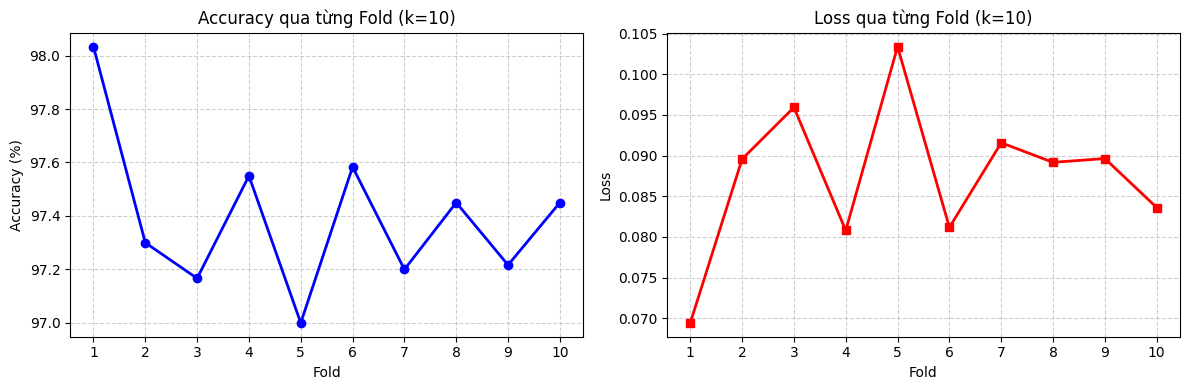

In [5]:
# CÂU g)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

plt.figure(figsize=(12, 4))

# Biểu đồ Accuracy
plt.subplot(1, 2, 1)
plt.plot(range(1, 11), [acc * 100 for acc in accuracy_per_fold], marker='o', color='b', linewidth=2)
plt.title('Accuracy qua từng Fold (k=10)')
plt.xlabel('Fold')
plt.ylabel('Accuracy (%)')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(range(1, 11), loss_per_fold, marker='s', color='r', linewidth=2)
plt.title('Loss qua từng Fold (k=10)')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [6]:
# CÂU h)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

best_fold_index = int(np.argmax(accuracy_per_fold))
best_model = models[best_fold_index]

print(f"Fold có Accuracy cao nhất: Fold {best_fold_index + 1}")
print(f"Accuracy tương ứng: {accuracy_per_fold[best_fold_index]*100:.2f}%")
print(f"Loss tương ứng:     {loss_per_fold[best_fold_index]:.4f}")

# Dự đoán nhãn cho toàn bộ tập test
y_prob_test = best_model.predict(test_images)
y_pred_test = np.argmax(y_prob_test, axis=1)
print("Đã hoàn tất phân lớp cho tập test!")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Fold có Accuracy cao nhất: Fold 1
Accuracy tương ứng: 98.03%
Loss tương ứng:     0.0694
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Đã hoàn tất phân lớp cho tập test!


In [7]:
# CÂU i)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

test_accuracy = accuracy_score(test_labels, y_pred_test)
print(f"Độ chính xác (Accuracy) của mô hình tốt nhất trên tập test: {test_accuracy * 100:.2f}%")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Độ chính xác (Accuracy) của mô hình tốt nhất trên tập test: 97.67%


In [8]:
# CÂU j)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

print("--- BÁO CÁO CHI TIẾT (PRECISION, RECALL, F1-SCORE TỪNG LỚP & TRUNG BÌNH) ---")
print(classification_report(test_labels, y_pred_test, digits=4))

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
--- BÁO CÁO CHI TIẾT (PRECISION, RECALL, F1-SCORE TỪNG LỚP & TRUNG BÌNH) ---
              precision    recall  f1-score   support

           0     0.9778    0.9867    0.9822       980
           1     0.9766    0.9930    0.9847      1135
           2     0.9776    0.9748    0.9762      1032
           3     0.9640    0.9812    0.9725      1010
           4     0.9825    0.9745    0.9785       982
           5     0.9764    0.9731    0.9747       892
           6     0.9762    0.9833    0.9797       958
           7     0.9802    0.9630    0.9715      1028
           8     0.9821    0.9600    0.9709       974
           9     0.9743    0.9752    0.9747      1009

    accuracy                         0.9767     10000
   macro avg     0.9768    0.9765    0.9766     10000
weighted avg     0.9767    0.9767    0.9767     10000



Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


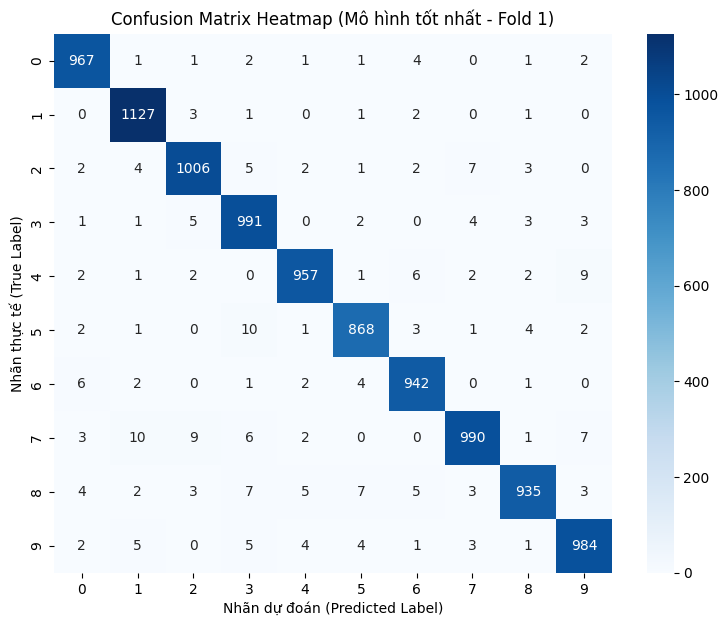

In [9]:
# CÂU k)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

cm = confusion_matrix(test_labels, y_pred_test)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix Heatmap (Mô hình tốt nhất - Fold {best_fold_index + 1})")
plt.xlabel("Nhãn dự đoán (Predicted Label)")
plt.ylabel("Nhãn thực tế (True Label)")
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


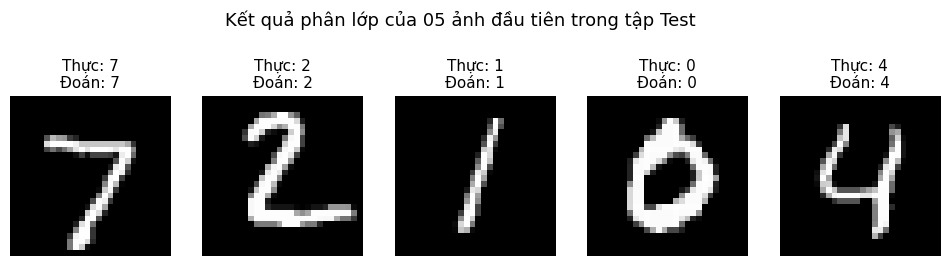

In [10]:
# CÂU l)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    img = test_images[i]
    sample = np.expand_dims(img, axis=0)
    pred_prob = best_model.predict(sample, verbose=0)
    pred_class = np.argmax(pred_prob)

    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Thực: {test_labels[i]}\nĐoán: {pred_class}", fontsize=11)
    axes[i].axis('off')

plt.suptitle("Kết quả phân lớp của 05 ảnh đầu tiên trong tập Test", fontsize=13, y=1.05)
plt.show()